## Premières manipulations de données

Reprise du modèle en rajoutant 4 features faciles à rajouter. Le centre est ajouté plus loin sous forme d'indicateurs binaires.

In [1]:
# Import necessary libraries
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
from sklearn.model_selection import train_test_split
from sksurv.ensemble import RandomSurvivalForest
from sksurv.linear_model import CoxPHSurvivalAnalysis
from sksurv.metrics import concordance_index_censored , concordance_index_ipcw
from sklearn.impute import SimpleImputer
from sksurv.util import Surv

from iscn_authenticator import validate_karyotype

from time import time

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sksurv.metrics import as_concordance_index_ipcw_scorer

from sksurv.ensemble import GradientBoostingSurvivalAnalysis
from sksurv.metrics import concordance_index_ipcw


# Clinical Data
df = pd.read_csv("./clinical_train.csv")
df_test = pd.read_csv("./clinical_test.csv")

# Molecular Data
maf_df = pd.read_csv("./molecular_train.csv", dtype={"CHR": str})
maf_df_test = pd.read_csv("./molecular_test.csv", dtype={"CHR": str})
# Train + test réunis : sert uniquement à calculer des features par patient (aucune cible utilisée)
maf_all = pd.concat([maf_df, maf_df_test], ignore_index=True)


# Target Data
target_df = pd.read_csv("./target_train.csv")

In [2]:
# Drop rows where 'OS_YEARS' is NaN if conversion caused any issues
target_df.dropna(subset=['OS_YEARS', 'OS_STATUS'], inplace=True)

# Check the data types to ensure 'OS_STATUS' is boolean and 'OS_YEARS' is numeric
print(target_df[['OS_STATUS', 'OS_YEARS']].dtypes)

# Contarget_dfvert 'OS_YEARS' to numeric if it isn’t already
target_df['OS_YEARS'] = pd.to_numeric(target_df['OS_YEARS'], errors='coerce')

# Ensure 'OS_STATUS' is boolean
target_df['OS_STATUS'] = target_df['OS_STATUS'].astype(bool)

# Select features
features = ['BM_BLAST', 'WBC', 'ANC', 'HB', 'PLT', 'MONOCYTES']
target = ['OS_YEARS', 'OS_STATUS']

# Create the survival data format
data = df.merge(target_df, on="ID")
X = data[features]
y = Surv.from_dataframe("OS_STATUS", "OS_YEARS", data)

print(X[:10])
y[:10]

OS_STATUS    float64
OS_YEARS     float64
dtype: object
   BM_BLAST    WBC   ANC    HB    PLT  MONOCYTES
0      14.0    2.8   0.2   7.6  119.0       0.70
1       1.0    7.4   2.4  11.6   42.0       0.10
2      15.0    3.7   2.1  14.2   81.0       0.10
3       1.0    3.9   1.9   8.9   77.0       0.10
4       6.0  128.0   9.7  11.1  195.0       0.90
5       3.0   15.8  12.6   8.0  492.0       0.88
6      12.0    6.2   3.0   9.6   61.0       0.80
7      15.0    4.8   1.5   9.4  142.0       0.70
8      14.0    0.8   0.2   8.8   23.0       0.00
9      14.0    1.4   0.2   7.4  183.0       0.00


array([( True, 1.11506849), (False, 4.92876712), (False, 2.04383562),
       ( True, 2.47671233), (False, 3.14520548), ( True, 2.01369863),
       (False, 0.8109589 ), ( True, 1.84931507), ( True, 1.00547945),
       (False, 0.29315068)],
      dtype=[('OS_STATUS', '?'), ('OS_YEARS', '<f8')])

# Exploration des données

Avant toute modélisation : description de la cible (censure, survie), des variables cliniques (distributions, valeurs manquantes, pouvoir discriminant univarié), des données moléculaires, du caryotype et des centres. Les figures de cette section sont reprises dans le rapport.

In [3]:
# Fonctions utilitaires : Kaplan-Meier et C-index de Harrell univarié
def kaplan_meier(time, event):
    d = pd.DataFrame({"t": np.asarray(time), "e": np.asarray(event)})
    times = np.sort(d["t"].unique())
    S, curve = 1.0, [(0.0, 1.0)]
    for u in times:
        at_risk = (d["t"] >= u).sum()
        deaths = ((d["t"] == u) & (d["e"] == 1)).sum()
        if deaths:
            S *= 1 - deaths / at_risk
        curve.append((u, S))
    return np.array(curve)

def km_at(curve, t):
    return curve[curve[:, 0] <= t][-1, 1]

def km_median(curve):
    below = curve[curve[:, 1] <= 0.5]
    return below[0, 0] if len(below) else np.nan

def harrell_univariate(time, event, risk):
    time, event, risk = map(np.asarray, (time, event, risk))
    conc = disc = tie = 0
    for i in np.where(event == 1)[0]:
        later = time > time[i]
        conc += (risk[i] > risk[later]).sum()
        disc += (risk[i] < risk[later]).sum()
        tie += (risk[i] == risk[later]).sum()
    return (conc + 0.5 * tie) / (conc + disc + tie)

print(f"Patients : train {len(df)} | test {len(df_test)}")
print(f"Mutations : train {len(maf_df)} lignes | test {len(maf_df_test)} lignes")
print(f"Cibles manquantes retirées : {len(df) - len(target_df)}")


Patients : train 3323 | test 1193
Mutations : train 10935 lignes | test 3089 lignes
Cibles manquantes retirées : 150


Décès observés : 50.4%  |  censurés : 49.6%
Médiane de survie (KM) : 3.15 ans
Survie à 1 / 2 / 5 ans : 79% / 61% / 36%
Suivi médian (KM inversé) : 3.84 ans
Patients observés au-delà de tau = 7 ans : 5.4%
OS_YEARS médian : décédés 1.38 | censurés 2.27


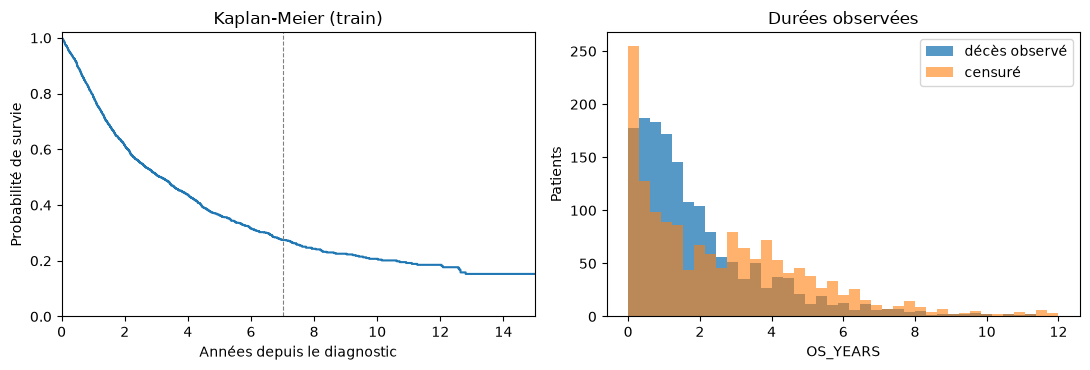

In [4]:
# Cible : censure et survie
t_os, t_ev = target_df["OS_YEARS"], target_df["OS_STATUS"].astype(int)
km_all = kaplan_meier(t_os, t_ev)
km_follow = kaplan_meier(t_os, 1 - t_ev)  # Kaplan-Meier inversé = suivi

print(f"Décès observés : {t_ev.mean():.1%}  |  censurés : {1 - t_ev.mean():.1%}")
print(f"Médiane de survie (KM) : {km_median(km_all):.2f} ans")
print(f"Survie à 1 / 2 / 5 ans : {km_at(km_all, 1):.0%} / {km_at(km_all, 2):.0%} / {km_at(km_all, 5):.0%}")
print(f"Suivi médian (KM inversé) : {km_median(km_follow):.2f} ans")
print(f"Patients observés au-delà de tau = 7 ans : {(t_os > 7).mean():.1%}")
print(f"OS_YEARS médian : décédés {t_os[t_ev == 1].median():.2f} | censurés {t_os[t_ev == 0].median():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].step(km_all[:, 0], km_all[:, 1], where="post")
ax[0].axvline(7, ls="--", color="grey", lw=0.8)
ax[0].set(xlabel="Années depuis le diagnostic", ylabel="Probabilité de survie",
          title="Kaplan-Meier (train)", xlim=(0, 15), ylim=(0, 1.02))
bins = np.linspace(0, 12, 40)
ax[1].hist(t_os[t_ev == 1], bins=bins, alpha=0.75, label="décès observé")
ax[1].hist(t_os[t_ev == 0], bins=bins, alpha=0.6, label="censuré")
ax[1].set(xlabel="OS_YEARS", ylabel="Patients", title="Durées observées")
ax[1].legend()
plt.tight_layout()
plt.show()


,mean,50%,min,max,manquants_train_%,manquants_test_%,c_index_univarie
BM_BLAST,5.983,3.00,0.0,91.00,3.280,9.640,0.631
WBC,6.535,4.10,0.2,154.40,8.185,9.388,0.472
ANC,3.265,2.00,0.0,109.62,5.808,11.819,0.463
MONOCYTES,0.956,0.37,0.0,44.20,18.086,74.015,0.474
HB,9.894,9.70,4.0,16.60,3.310,9.304,0.397
PLT,167.049,123.00,2.0,1451.00,3.732,9.640,0.369


C-index < 0.5 : variable protectrice (plus la valeur est haute, plus le risque est faible)
C-index univarié du nombre de mutations : 0.602


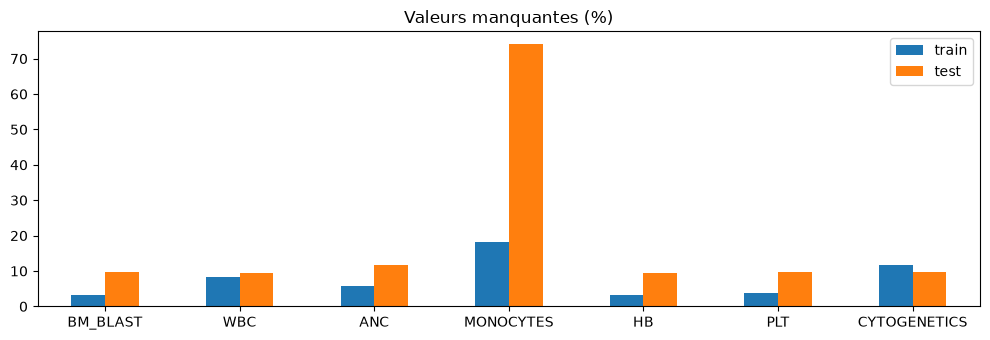

In [5]:
# Variables cliniques : statistiques, valeurs manquantes (train vs test), C-index univarié
clin = ["BM_BLAST", "WBC", "ANC", "MONOCYTES", "HB", "PLT"]
merged = target_df.merge(df, on="ID")
n_mut = maf_df.groupby("ID").size()

summary = df[clin].describe().T[["mean", "50%", "min", "max"]]
summary["manquants_train_%"] = df[clin].isna().mean() * 100
summary["manquants_test_%"] = df_test[clin].isna().mean() * 100
summary["c_index_univarie"] = [
    harrell_univariate(merged["OS_YEARS"], merged["OS_STATUS"], merged[c].fillna(merged[c].median()))
    for c in clin
]
display(summary.round(3))
print("C-index < 0.5 : variable protectrice (plus la valeur est haute, plus le risque est faible)")
print(f"C-index univarié du nombre de mutations : "
      f"{harrell_univariate(merged['OS_YEARS'], merged['OS_STATUS'], merged['ID'].map(n_mut).fillna(0)):.3f}")

na = pd.DataFrame({
    "train": df[clin + ["CYTOGENETICS"]].isna().mean() * 100,
    "test": df_test[clin + ["CYTOGENETICS"]].isna().mean() * 100,
})
na.plot.bar(figsize=(10, 3.5), rot=0, title="Valeurs manquantes (%)")
plt.tight_layout()
plt.show()


Mutations par patient : moyenne 3.29, médiane 3, max 17 ; patients sans mutation : 8.9%
Gènes distincts : 124
Variants exacts (5-uplets) distincts : 5282, dont 79% vus chez un seul patient

Effets :
EFFECT
non_synonymous_codon            5471
frameshift_variant              2877
stop_gained                     1673
splice_site_variant              512
inframe_codon_loss               168
PTD                               89
inframe_codon_gain                55
ITD                               26
initiator_codon_change            24
2KB_upstream_variant              12
complex_change_in_transcript      11
3_prime_UTR_variant                5
stop_lost                          4
inframe_variant                    4
synonymous_codon                   3
stop_retained_variant              1


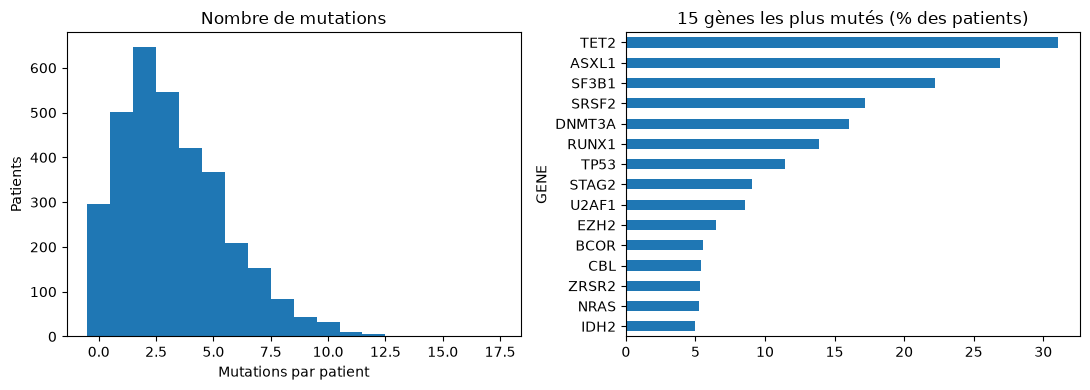

In [6]:
# Données moléculaires
mut_per_patient = maf_df.groupby("ID").size().reindex(df["ID"], fill_value=0)
print(f"Mutations par patient : moyenne {mut_per_patient.mean():.2f}, médiane {mut_per_patient.median():.0f}, "
      f"max {mut_per_patient.max()} ; patients sans mutation : {(mut_per_patient == 0).mean():.1%}")
print(f"Gènes distincts : {maf_df['GENE'].nunique()}")

variants = (maf_df.dropna(subset=["CHR", "START", "END", "REF", "ALT"])
            .drop_duplicates(["ID", "CHR", "START", "END", "REF", "ALT"])
            .groupby(["CHR", "START", "END", "REF", "ALT"]).size())
print(f"Variants exacts (5-uplets) distincts : {len(variants)}, dont {(variants == 1).mean():.0%} vus chez un seul patient")
print("\nEffets :")
print(maf_df["EFFECT"].value_counts().to_string())

gene_freq = maf_df.drop_duplicates(["ID", "GENE"])["GENE"].value_counts().head(15) / len(df) * 100
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(mut_per_patient, bins=np.arange(0, 19) - 0.5)
ax[0].set(xlabel="Mutations par patient", ylabel="Patients", title="Nombre de mutations")
gene_freq[::-1].plot.barh(ax=ax[1], title="15 gènes les plus mutés (% des patients)")
plt.tight_layout()
plt.show()


Caryotype manquant : 11.6% | normal (parmi les renseignés) : 59.4%
Catégories de risque (0 favorable, 1 intermédiaire, 2 défavorable, NaN absent) :
cyto_risk
1.0    2344
2.0     591
NaN     387
0.0       1
intermédiaire     n=2240  survie à 2 ans : 68%
défavorable       n=584   survie à 2 ans : 40%
caryotype absent  n=348   survie à 2 ans : 58%


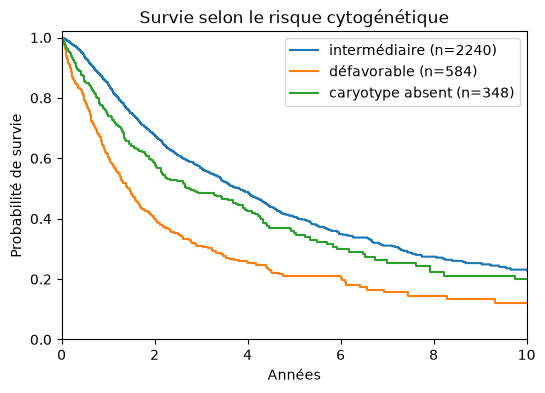

In [7]:
# Caryotype : parsing (cyto.py) et survie selon la catégorie de risque
from cyto import cyto_features

cyto_train = cyto_features(df.set_index("ID")["CYTOGENETICS"])
print(f"Caryotype manquant : {cyto_train['cyto_missing'].mean():.1%} | "
      f"normal (parmi les renseignés) : {cyto_train['cyto_normal'].mean():.1%}")
print("Catégories de risque (0 favorable, 1 intermédiaire, 2 défavorable, NaN absent) :")
print(cyto_train["cyto_risk"].value_counts(dropna=False).to_string())

m = target_df.merge(cyto_train.reset_index(), on="ID", how="left")
groups = {"intermédiaire": m["cyto_risk"] == 1, "défavorable": m["cyto_risk"] == 2,
          "caryotype absent": m["cyto_missing"] == 1}
plt.figure(figsize=(6, 4))
for label, mask in groups.items():
    curve = kaplan_meier(m.loc[mask, "OS_YEARS"], m.loc[mask, "OS_STATUS"])
    print(f"{label:<17} n={mask.sum():<5} survie à 2 ans : {km_at(curve, 2):.0%}")
    plt.step(curve[:, 0], curve[:, 1], where="post", label=f"{label} (n={mask.sum()})")
plt.xlim(0, 10); plt.ylim(0, 1.02)
plt.xlabel("Années"); plt.ylabel("Probabilité de survie"); plt.title("Survie selon le risque cytogénétique")
plt.legend()
plt.show()


In [8]:
# Centres : hétérogénéité dans le train, centre du test
print("Centres du test :", df_test["CENTER"].value_counts().to_dict())
print("Centre(s) du test absent(s) du train :", sorted(set(df_test["CENTER"]) - set(df["CENTER"])))

by_center = merged.groupby("CENTER").agg(patients=("ID", "size"), deces_observes=("OS_STATUS", "mean"),
                                         os_median=("OS_YEARS", "median"))
by_center = by_center.sort_values("patients", ascending=False)
big = by_center[by_center["patients"] >= 50]
print(f"Décès observés parmi les centres d'au moins 50 patients : "
      f"de {big['deces_observes'].min():.0%} à {big['deces_observes'].max():.0%}")
display(by_center.round(3))


Centres du test : {'KYW': 1193}
Centre(s) du test absent(s) du train : ['KYW']
Décès observés parmi les centres d'au moins 50 patients : de 11% à 92%


,patients,deces_observes,os_median
CENTER,,,
KI,820,0.612,2.434
DUS,445,0.647,1.630
PV,316,0.256,1.052
GESMD,245,0.457,1.485
RMCN,199,0.578,1.953
CCH,140,0.236,1.793
CGM,107,0.346,0.962
ROM,103,0.107,1.151
UOB,87,0.805,2.296


**Bilan de l'exploration**
- La moitié des patients sont censurés (50,4 % de décès observés). La médiane de survie est de 3,1 ans et seuls ~5 % des patients sont suivis au-delà de 7 ans, d'où τ = 7 dans la métrique.
- Les variables cliniques sont très asymétriques. BM_BLAST est la plus discriminante seule ; PLT et HB sont protectrices.
- **Décalage train/test** : le test vient d'un seul centre (KYW) **absent du train**, et MONOCYTES y manque chez 74 % des patients (18 % dans le train).
- Les données moléculaires sont denses au niveau du gène (TET2 31 %, ASXL1 27 %, SF3B1 22 %…) mais très creuses au niveau du variant exact : ~79 % des 5-uplets ne sont vus que chez un patient.
- Le caryotype défavorable est nettement pronostique. Le groupe favorable ne contient qu'un patient, donc la catégorie de risque est en pratique binaire.
- Les centres du train sont très hétérogènes (11 % à 92 % de décès observés), ce qui reflète surtout des durées de suivi différentes : les indicateurs de centre risquent de ne pas se généraliser au test.

In [9]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [10]:
# Survival-aware imputation for missing values
imputer = SimpleImputer(strategy="median")
X_train[features] = imputer.fit_transform(X_train[features])
X_test[features] = imputer.transform(X_test[features])

Fonctions d'évaluation utilisées à chaque étape de feature engineering : LightGBM (régression sur `OS_YEARS`, ignore la censure) et un Cox légèrement pénalisé (prend en compte la censure).

In [11]:
import lightgbm as lgb

def eval_lgb(X_tr, X_te):
    params = {'max_depth': 3, 'learning_rate': 0.05, 'verbose': -1}
    lgb_model = lgb.train(params=params, train_set=lgb.Dataset(X_tr, label=y_train['OS_YEARS']))
    ci_tr = concordance_index_ipcw(y_train, y_train, -lgb_model.predict(X_tr), tau=7)[0]
    ci_te = concordance_index_ipcw(y_train, y_test, -lgb_model.predict(X_te), tau=7)[0]
    print(f"LightGBM IPCW C-index  train : {ci_tr:.4f}   test : {ci_te:.4f}")

def eval_cox(X_tr, X_te, alpha=1.0):
    cox = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", CoxPHSurvivalAnalysis(alpha=alpha)),
    ])
    cox.fit(X_tr, y_train)
    ci_tr = concordance_index_ipcw(y_train, y_train, cox.predict(X_tr), tau=7)[0]
    ci_te = concordance_index_ipcw(y_train, y_test, cox.predict(X_te), tau=7)[0]
    print(f"Cox      IPCW C-index  train : {ci_tr:.4f}   test : {ci_te:.4f}")

In [30]:
# Import necessary libraries
import lightgbm as lgb
from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv

# Define LightGBM parameters
lgbm_params = {
    'max_depth': 3,
    'learning_rate': 0.05,
    'verbose': -1
}

# Prepare the data for LightGBM
# Scale the target (OS_YEARS) to reduce skew, apply weights based on event status
X_train_lgb = X_train  # Features for training
y_train_transformed = y_train['OS_YEARS']

# Create LightGBM dataset
train_dataset = lgb.Dataset(X_train_lgb, label=y_train_transformed)

# Train the LightGBM model
model = lgb.train(params=lgbm_params, train_set=train_dataset)

# Make predictions on the training and testing sets
pred_train = -model.predict(X_train)
pred_test = -model.predict(X_test)

# Evaluate the model using Concordance Index IPCW
train_ci_ipcw = concordance_index_ipcw(y_train, y_train, pred_train, tau=7)[0]
test_ci_ipcw = concordance_index_ipcw(y_train, y_test, pred_test, tau=7)[0]
print(f"LightGBM Survival Model Concordance Index IPCW on train: {train_ci_ipcw}")
print(f"LightGBM Survival Model Concordance Index IPCW on test: {test_ci_ipcw}")

eval_cox(X_train, X_test)

LightGBM Survival Model Concordance Index IPCW on train: 0.7019572670336214
LightGBM Survival Model Concordance Index IPCW on test: 0.6580427600248292
Cox      IPCW C-index  train : 0.6663   test : 0.6640


Premier gain de 1% sur les données test et les données d'entraînement...

<Figure size 2000x1000 with 0 Axes>

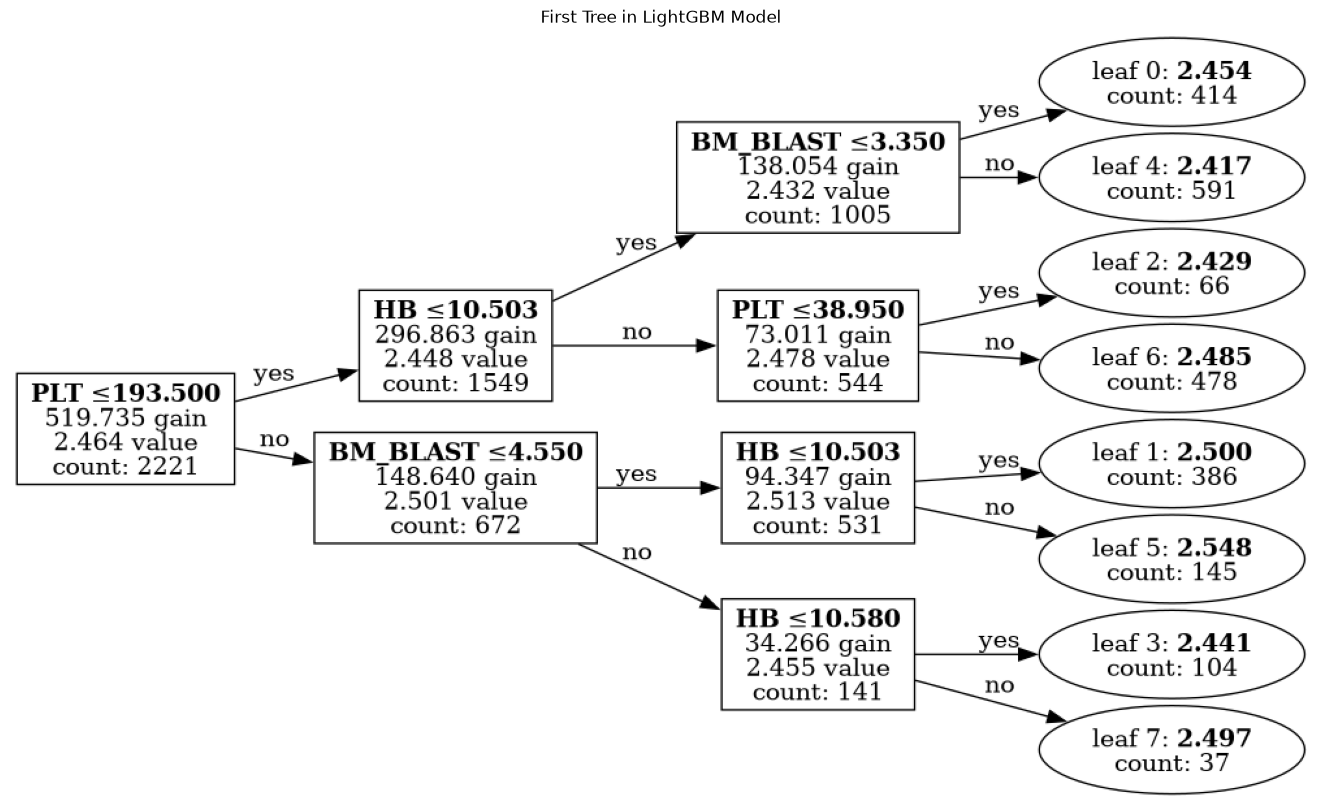

In [31]:
# Assuming the LightGBM model is defined as `model`
plt.figure(figsize=(20, 10))
lgb.plot_tree(model, tree_index=0, figsize=(20, 10), show_info=['split_gain', 'internal_value', 'internal_count', 'leaf_count'])
plt.title("First Tree in LightGBM Model")
plt.show()

## Un peu de feature engineering

l'objectif ici est avant d'appliquer des modèles de commencer par essayer de former un ensemble de données le plus pertinent et complet possible

# Extraction des informations depuis les données moléculaires

On se propose de reprendre le principe du "Step 5" du benchmark en un peu plus sophistiqué. On va essayer de rajouter des features à partir des données EFFECT en comptabilisant uniquement les effets qui ont des conséquences sur la production des protéines : non_synonymous_codon, frameshift_variant, stop_gained, splice_site_variant, inframe_codon_loss, inframe_codon_gain, PTD, ITD et initiator_codon_change. Les autres effets de mutations sont à priori négligeables. L'idée : compter le nombre de mutations de chaque type pour chaque patient en considérant que cette cractéristique est liée au risque de mort par leucémie.

In [32]:
mutation_effects = [
    'non_synonymous_codon',
    'frameshift_variant',
    'stop_gained',
    'splice_site_variant',
    'inframe_codon_loss',
    'inframe_codon_gain',
    'PTD',
    'ITD',
    'initiator_codon_change',
]
mutation_counts = (
    maf_all.loc[maf_all['EFFECT'].isin(mutation_effects)]
    .groupby(['ID', 'EFFECT'])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=mutation_effects, fill_value=0)
)

def add_effect_counts(X_part, ids):
    counts = mutation_counts.reindex(ids, fill_value=0)
    counts.index = X_part.index
    return X_part.join(counts)

X_augmented = add_effect_counts(X, data['ID'].to_numpy())

print(X_augmented[:10])

   BM_BLAST      WBC     ANC      HB      PLT  MONOCYTES  \
0   14.0000   2.8000  0.2000  7.6000 119.0000     0.7000   
1    1.0000   7.4000  2.4000 11.6000  42.0000     0.1000   
2   15.0000   3.7000  2.1000 14.2000  81.0000     0.1000   
3    1.0000   3.9000  1.9000  8.9000  77.0000     0.1000   
4    6.0000 128.0000  9.7000 11.1000 195.0000     0.9000   
5    3.0000  15.8000 12.6000  8.0000 492.0000     0.8800   
6   12.0000   6.2000  3.0000  9.6000  61.0000     0.8000   
7   15.0000   4.8000  1.5000  9.4000 142.0000     0.7000   
8   14.0000   0.8000  0.2000  8.8000  23.0000     0.0000   
9   14.0000   1.4000  0.2000  7.4000 183.0000     0.0000   

   non_synonymous_codon  frameshift_variant  stop_gained  splice_site_variant  \
0                     5                   3            1                    0   
1                     0                   2            1                    0   
2                     1                   0            2                    0   
3              

In [33]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_augmented, y, test_size=0.3, random_state=42)


# Survival-aware imputation for missing values
imputer = SimpleImputer(strategy="median")
X_train[features] = imputer.fit_transform(X_train[features])
X_test[features] = imputer.transform(X_test[features])

# Define LightGBM parameters
lgbm_params = {
    'max_depth': 3,
    'learning_rate': 0.05,
    'verbose': -1
}

# Prepare the data for LightGBM
# Scale the target (OS_YEARS) to reduce skew, apply weights based on event status
X_train_lgb = X_train  # Features for training
y_train_transformed = y_train['OS_YEARS']

# Create LightGBM dataset
train_dataset = lgb.Dataset(X_train_lgb, label=y_train_transformed)

# Train the LightGBM model
model = lgb.train(params=lgbm_params, train_set=train_dataset)

# Make predictions on the training and testing sets
pred_train = -model.predict(X_train)
pred_test = -model.predict(X_test)

# Evaluate the model using Concordance Index IPCW
train_ci_ipcw = concordance_index_ipcw(y_train, y_train, pred_train, tau=7)[0]
test_ci_ipcw = concordance_index_ipcw(y_train, y_test, pred_test, tau=7)[0]
print(f"LightGBM Survival Model Concordance Index IPCW on train: {train_ci_ipcw}")
print(f"LightGBM Survival Model Concordance Index IPCW on test: {test_ci_ipcw}")

eval_cox(X_train, X_test)

LightGBM Survival Model Concordance Index IPCW on train: 0.7190120728554696
LightGBM Survival Model Concordance Index IPCW on test: 0.6730360941433513
Cox      IPCW C-index  train : 0.6867   test : 0.6807


Encore un gain de 2% pour le train set et 1% pour le test set. Cependant, cette création de feature semble toujours assez naïve puisque l'on récupère uniquement de l'information sur la mesure et la manière dans laquelle le patient a été touché par des mutations toujours sans savoir exactement lesquelles.

Il pourrait être pertinent de trouver un moyen de sélectionner les mutations qui peuvent avoir un lien avec la leucémie. Une première idée pourrait être de prendre les N premières mutations les plus représentées parmi les patients qui sont décédés après leur diagnostique (ici la censure nous empêche peut-être de prendre en compte d'autres mutations). On caractérise une mutation par le 5-uplet (CHR, START, END, REF, ALT).

In [34]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_augmented, y, test_size=0.3, random_state=42)


# Survival-aware imputation for missing values
imputer = SimpleImputer(strategy="median")
X_train[features] = imputer.fit_transform(X_train[features])
X_test[features] = imputer.transform(X_test[features])

#nombre de mutations à prendre en compte (peut être modifié pour tester l'optimisation)
N=30

# IDs patients des deux parties du split (les index de X viennent de `data`)
ids_train = data.loc[X_train.index, 'ID'].to_numpy()
ids_test = data.loc[X_test.index, 'ID'].to_numpy()

# 5-uplets (CHR, START, END, REF, ALT) triés par fréquence chez les patients décédés du TRAIN
mutation_columns = ['CHR', 'START', 'END', 'REF', 'ALT']

def count_5tuples(deceased_ids):
    return (
        maf_all.loc[maf_all['ID'].isin(deceased_ids)]
        .dropna(subset=mutation_columns)
        .groupby(mutation_columns)
        .size()
        .sort_values(ascending=False, kind='stable')
    )

mutation_5tuple_counts = count_5tuples(ids_train[y_train['OS_STATUS']])
mutation_5tuples_by_frequency = mutation_5tuple_counts.tolist()

print(f"{len(mutation_5tuples_by_frequency)} 5-uplets distincts")
mutation_5tuples_by_frequency[:30]

2432 5-uplets distincts


[166,
 127,
 102,
 59,
 57,
 53,
 38,
 34,
 34,
 31,
 29,
 29,
 24,
 22,
 20,
 17,
 17,
 15,
 15,
 15,
 13,
 12,
 12,
 12,
 12,
 11,
 11,
 11,
 10,
 10]

In [35]:
# Score de présence pondéré des N mutations les plus fréquentes
def add_rank_score(X_part, ids, top_counts):
    top = top_counts.reset_index(name='count')
    top['rank_weight'] = top['count'] / top['count'].max()
    scores = (
        maf_all.merge(top[mutation_columns + ['rank_weight']], on=mutation_columns, how='inner')
        .drop_duplicates(subset=['ID'] + mutation_columns)
        .groupby('ID')['rank_weight']
        .sum()
    )
    X_out = X_part.copy()
    X_out['mutation_rank_score'] = pd.Series(ids).map(scores).fillna(0.0).to_numpy()
    return X_out

top_mutations = mutation_5tuple_counts.head(N)
X_train_aug = add_rank_score(X_train, ids_train, top_mutations)
X_test_aug = add_rank_score(X_test, ids_test, top_mutations)
X_train_aug.head()

,BM_BLAST,WBC,ANC,HB,PLT,MONOCYTES,non_synonymous_codon,frameshift_variant,stop_gained,splice_site_variant,inframe_codon_loss,inframe_codon_gain,PTD,ITD,initiator_codon_change,mutation_rank_score
1018,3.0000,3.5000,0.8400,9.1000,150.0000,1.0500,1,3,0,1,0,0,0,0,0,0.0000
1862,15.0000,4.0000,2.0000,11.0000,45.0000,0.0000,2,1,1,0,1,0,0,0,0,0.6145
195,6.0000,2.7000,0.9450,6.9000,132.0000,0.1700,2,0,0,0,0,0,0,0,0,0.0000
2008,2.0000,2.0000,1.0000,10.0000,178.0000,0.0000,4,0,0,0,0,0,0,0,0,0.4940
2023,10.0000,2.0000,1.0000,10.0000,53.0000,0.0000,1,0,0,0,0,0,0,0,0,0.0000


In [36]:
# Define LightGBM parameters
lgbm_params = {
    'max_depth': 3,
    'learning_rate': 0.05,
    'verbose': -1
}

# Prepare the data for LightGBM
# Scale the target (OS_YEARS) to reduce skew, apply weights based on event status
X_train_lgb = X_train_aug  # Features for training
y_train_transformed = y_train['OS_YEARS']

# Create LightGBM dataset
train_dataset = lgb.Dataset(X_train_lgb, label=y_train_transformed)

# Train the LightGBM model
model = lgb.train(params=lgbm_params, train_set=train_dataset)

# Make predictions on the training and testing sets
pred_train = -model.predict(X_train_lgb)
pred_test = -model.predict(X_test_aug)

# Evaluate the model using Concordance Index IPCW
train_ci_ipcw = concordance_index_ipcw(y_train, y_train, pred_train, tau=7)[0]
test_ci_ipcw = concordance_index_ipcw(y_train, y_test, pred_test, tau=7)[0]
print(f"LightGBM Survival Model Concordance Index IPCW on train: {train_ci_ipcw}")
print(f"LightGBM Survival Model Concordance Index IPCW on test: {test_ci_ipcw}")

eval_cox(X_train_aug, X_test_aug)

LightGBM Survival Model Concordance Index IPCW on train: 0.7198841074896225
LightGBM Survival Model Concordance Index IPCW on test: 0.6730729336513753
Cox      IPCW C-index  train : 0.6857   test : 0.6795


Finalement on va voir si il n'est pas plus pertinent de rajouter 30 features booléennes qui disent si oui ou non le patient a cette mutation génétique (on essaie de rester en dessus de 1 feature pour 10 observations)

In [37]:
# Ajouter une colonne binaire pour chacune des N mutations les plus fréquentes (sélectionnées sur le train)
def add_mutation_flags(X_part, ids, top_counts):
    top = top_counts.reset_index()[mutation_columns]
    top['feature_name'] = [f'mutation_{rank:02d}' for rank in range(1, len(top) + 1)]
    presence = (
        maf_all.merge(top, on=mutation_columns, how='inner')
        .drop_duplicates(subset=['ID', 'feature_name'])
        .assign(present=1)
        .pivot(index='ID', columns='feature_name', values='present')
    )
    flags = presence.reindex(index=ids, columns=top['feature_name']).fillna(0).astype('uint8')
    flags.index = X_part.index
    return X_part.join(flags)

X_train_aug2 = add_mutation_flags(X_train_aug, ids_train, top_mutations)
X_test_aug2 = add_mutation_flags(X_test_aug, ids_test, top_mutations)
X_train_aug2.head()

,BM_BLAST,WBC,ANC,HB,PLT,MONOCYTES,non_synonymous_codon,frameshift_variant,stop_gained,splice_site_variant,...,mutation_21,mutation_22,mutation_23,mutation_24,mutation_25,mutation_26,mutation_27,mutation_28,mutation_29,mutation_30
1018,3.0000,3.5000,0.8400,9.1000,150.0000,1.0500,1,3,0,1,...,0,0,0,0,0,0,0,0,0,0
1862,15.0000,4.0000,2.0000,11.0000,45.0000,0.0000,2,1,1,0,...,0,0,0,0,0,0,0,0,0,0
195,6.0000,2.7000,0.9450,6.9000,132.0000,0.1700,2,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2008,2.0000,2.0000,1.0000,10.0000,178.0000,0.0000,4,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2023,10.0000,2.0000,1.0000,10.0000,53.0000,0.0000,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [38]:
# Define LightGBM parameters
lgbm_params = {
    'max_depth': 3,
    'learning_rate': 0.05,
    'verbose': -1
}

# Prepare the data for LightGBM
# Scale the target (OS_YEARS) to reduce skew, apply weights based on event status
X_train_lgb = X_train_aug2  # Features for training
y_train_transformed = y_train['OS_YEARS']

# Create LightGBM dataset
train_dataset = lgb.Dataset(X_train_lgb, label=y_train_transformed)

# Train the LightGBM model
model = lgb.train(params=lgbm_params, train_set=train_dataset)

# Make predictions on the training and testing sets
pred_train = -model.predict(X_train_lgb)
pred_test = -model.predict(X_test_aug2)

# Evaluate the model using Concordance Index IPCW
train_ci_ipcw = concordance_index_ipcw(y_train, y_train, pred_train, tau=7)[0]
test_ci_ipcw = concordance_index_ipcw(y_train, y_test, pred_test, tau=7)[0]
print(f"LightGBM Survival Model Concordance Index IPCW on train: {train_ci_ipcw}")
print(f"LightGBM Survival Model Concordance Index IPCW on test: {test_ci_ipcw}")

eval_cox(X_train_aug2, X_test_aug2)

LightGBM Survival Model Concordance Index IPCW on train: 0.7182148314332645
LightGBM Survival Model Concordance Index IPCW on test: 0.6738141797108559
Cox      IPCW C-index  train : 0.6924   test : 0.6783


Impossible de dire si cela est mieux pour le moment, mais on garde.

# Indicateurs par gène et VAF maximale

Pour les 40 gènes mutés chez le plus de patients (comptés sur tous les patients du train, sans regarder la cible) : un indicateur binaire de présence et la VAF maximale du patient pour ce gène (0 si le gène n'est pas muté).

In [39]:
N_GENES = 40
top_genes = (
    maf_df.drop_duplicates(subset=['ID', 'GENE'])['GENE']
    .value_counts()
    .head(N_GENES)
    .index.tolist()
)

def add_gene_features(X_part, ids, genes):
    m = maf_all[maf_all['GENE'].isin(genes)]
    flags = pd.crosstab(m['ID'], m['GENE']).clip(upper=1).add_prefix('gene_')
    vaf = m.groupby(['ID', 'GENE'])['VAF'].max().unstack().add_prefix('vaf_')
    columns = [f'{prefix}{g}' for g in genes for prefix in ('gene_', 'vaf_')]
    feats = flags.join(vaf).reindex(index=ids, columns=columns).fillna(0)
    feats.index = X_part.index
    return X_part.join(feats)

X_train_aug3 = add_gene_features(X_train_aug2, ids_train, top_genes)
X_test_aug3 = add_gene_features(X_test_aug2, ids_test, top_genes)
X_train_aug3.head()

,BM_BLAST,WBC,ANC,HB,PLT,MONOCYTES,non_synonymous_codon,frameshift_variant,stop_gained,splice_site_variant,...,gene_BCORL1,vaf_BCORL1,gene_WT1,vaf_WT1,gene_FLT3,vaf_FLT3,gene_CTCF,vaf_CTCF,gene_ZBTB33,vaf_ZBTB33
1018,3.0000,3.5000,0.8400,9.1000,150.0000,1.0500,1,3,0,1,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1862,15.0000,4.0000,2.0000,11.0000,45.0000,0.0000,2,1,1,0,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
195,6.0000,2.7000,0.9450,6.9000,132.0000,0.1700,2,0,0,0,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2008,2.0000,2.0000,1.0000,10.0000,178.0000,0.0000,4,0,0,0,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2023,10.0000,2.0000,1.0000,10.0000,53.0000,0.0000,1,0,0,0,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


In [40]:
eval_lgb(X_train_aug3, X_test_aug3)
eval_cox(X_train_aug3, X_test_aug3)

LightGBM IPCW C-index  train : 0.7397   test : 0.6895
Cox      IPCW C-index  train : 0.7305   test : 0.6793


# Parsing de la colonne Cytogenetics

Le fichier `cyto.py` (dans le dossier du notebook) découpe chaque caryotype en clones et en anomalies, puis en tire des features : caryotype normal, nombre d'anomalies, caryotype complexe ou monosomal, anomalies de la classification ELN 2022 et une catégorie de risque (0 favorable, 1 intermédiaire, 2 défavorable). Les patients sans caryotype ont `cyto_missing = 1` et des NaN ailleurs (imputés par la médiane pour Cox et GBSA).

In [41]:
from cyto import cyto_features

cyto_all = pd.concat([df, df_test]).set_index('ID')['CYTOGENETICS']

def add_cyto_features(X_part, ids):
    feats = cyto_features(cyto_all.reindex(ids))
    feats.index = X_part.index
    return X_part.join(feats)

X_train_aug4 = add_cyto_features(X_train_aug3, ids_train)
X_test_aug4 = add_cyto_features(X_test_aug3, ids_test)
X_train_aug4.filter(like='cyto_').describe().T

,count,mean,std,min,25%,50%,75%,max
cyto_missing,2221.0000,0.1067,0.3088,0.0000,0.0000,0.0000,0.0000,1.0000
cyto_normal,1984.0000,0.5887,0.4922,0.0000,0.0000,1.0000,1.0000,1.0000
cyto_n_abn,1984.0000,0.9824,2.0677,0.0000,0.0000,0.0000,1.0000,16.0000
cyto_n_clones,1984.0000,1.3780,0.6776,1.0000,1.0000,1.0000,2.0000,6.0000
cyto_abn_frac,1591.0000,0.3153,0.4068,0.0000,0.0000,0.0000,0.7500,1.0000
cyto_complex,1984.0000,0.0948,0.2930,0.0000,0.0000,0.0000,0.0000,1.0000
cyto_t8_21,1984.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
cyto_inv16,1984.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
cyto_t15_17,1984.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
cyto_minus5_del5q,1984.0000,0.1290,0.3353,0.0000,0.0000,0.0000,0.0000,1.0000


In [42]:
eval_lgb(X_train_aug4, X_test_aug4)
eval_cox(X_train_aug4, X_test_aug4)

LightGBM IPCW C-index  train : 0.7459   test : 0.6891
Cox      IPCW C-index  train : 0.7376   test : 0.6883


# Indicateurs binaires pour CENTER

Une colonne par centre présent dans le train. Un patient d'un centre absent du train a toutes ses colonnes à 0.

In [43]:
centers = sorted(data['CENTER'].dropna().unique())
center_all = pd.concat([df, df_test]).set_index('ID')['CENTER']

def add_center_flags(X_part, ids):
    c = center_all.reindex(ids).to_numpy()
    flags = pd.DataFrame({f'center_{k}': (c == k).astype('uint8') for k in centers}, index=X_part.index)
    return X_part.join(flags)

X_train_aug5 = add_center_flags(X_train_aug4, ids_train)
X_test_aug5 = add_center_flags(X_test_aug4, ids_test)
print(f"{len(centers)} centres dans le train")

23 centres dans le train


In [44]:
eval_lgb(X_train_aug5, X_test_aug5)
eval_cox(X_train_aug5, X_test_aug5)

LightGBM IPCW C-index  train : 0.7130   test : 0.6674
Cox      IPCW C-index  train : 0.7428   test : 0.6880


# Sélection des groupes de features

On teste **toutes les combinaisons** des 6 groupes de features créés jusqu'ici (2⁶ = 64 combinaisons). Les features cliniques de base sont toujours gardées :

| groupe | contenu |
|---|---|
| `effets` | nombre de mutations par type d'effet |
| `rank_score` | score pondéré des N 5-uplets les plus fréquents chez les décédés |
| `mut_flags` | indicateurs des N 5-uplets les plus fréquents |
| `genes` | présence et VAF max des 40 gènes les plus mutés |
| `cyto` | features issues du caryotype |
| `centres` | indicateurs binaires du centre |

Pour éviter les biais :
- **validation croisée à 5 plis sur le train uniquement**. Le split test n'est pas utilisé pour choisir, sinon on finirait par sur-apprendre ce split.
- **`rank_score` et `mut_flags` sont recalculés dans chaque pli**, car ils utilisent la cible (patients décédés). Les calculer sur tout le train ferait fuiter l'information du pli de validation et gonflerait artificiellement leur score.
- deux modèles (LightGBM et Cox), car un groupe peut aider l'un et gêner l'autre.

Le second tableau donne l'**effet marginal** de chaque groupe : score moyen des combinaisons qui le contiennent moins score moyen de celles qui ne le contiennent pas. Une valeur négative est suspecte.
Les écarts plus petits que l'écart-type entre plis (~0,01) relèvent du bruit.

In [45]:
from itertools import combinations
import warnings

# Groupes qui n'utilisent pas la cible : calculés une fois sur tout le train
static_groups = {
    "effets": mutation_effects,
    "genes": [c for c in X_train_aug5.columns if c.startswith(("gene_", "vaf_"))],
    "cyto": [c for c in X_train_aug5.columns if "cyto_" in c],
    "centres": [c for c in X_train_aug5.columns if c.startswith("center_")],
}
# Groupes qui utilisent la cible (décédés) : recalculés dans chaque pli
cols_of = dict(
    static_groups,
    rank_score=["mutation_rank_score"],
    mut_flags=[f"mutation_{r:02d}" for r in range(1, N + 1)],
)
group_names = list(cols_of)

def target_features(ids_fit, y_fit, ids_part, index):
    top = count_5tuples(ids_fit[y_fit["OS_STATUS"]]).head(N)
    out = add_rank_score(pd.DataFrame(index=index), ids_part, top)
    return add_mutation_flags(out, ids_part, top)

def score_lgb(Xtr, Xva, y_tr, y_va):
    m = lgb.train({"max_depth": 3, "learning_rate": 0.05, "verbose": -1},
                  lgb.Dataset(Xtr, label=y_tr["OS_YEARS"]))
    return concordance_index_ipcw(y_tr, y_va, -m.predict(Xva), tau=7)[0]

def score_cox(Xtr, Xva, y_tr, y_va, alpha=1.0):
    cox = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", CoxPHSurvivalAnalysis(alpha=alpha)),
    ])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        cox.fit(Xtr, y_tr)
    return concordance_index_ipcw(y_tr, y_va, cox.predict(Xva), tau=7)[0]

# Préparation des 5 plis (features dépendant de la cible recalculées sur chaque pli d'entraînement)
X_static = X_train_aug5[features + [c for g in static_groups.values() for c in g]]
folds = []
for tr, va in KFold(n_splits=5, shuffle=True, random_state=0).split(X_static):
    ids_tr, y_tr, y_va = ids_train[tr], y_train[tr], y_train[va]
    Xtr = X_static.iloc[tr].join(target_features(ids_tr, y_tr, ids_tr, X_static.index[tr]))
    Xva = X_static.iloc[va].join(target_features(ids_tr, y_tr, ids_train[va], X_static.index[va]))
    folds.append((Xtr, Xva, y_tr, y_va))

# Évaluation des 64 combinaisons
start = time()
rows = []
for k in range(len(group_names) + 1):
    for combo in combinations(group_names, k):
        cols = features + [c for g in combo for c in cols_of[g]]
        s_lgb = [score_lgb(Xtr[cols], Xva[cols], y_tr, y_va) for Xtr, Xva, y_tr, y_va in folds]
        s_cox = [score_cox(Xtr[cols], Xva[cols], y_tr, y_va) for Xtr, Xva, y_tr, y_va in folds]
        row = {"groupes": " + ".join(combo) or "(base)", "n_feat": len(cols),
               "lgb": np.mean(s_lgb), "lgb_std": np.std(s_lgb),
               "cox": np.mean(s_cox), "cox_std": np.std(s_cox)}
        row.update({g: g in combo for g in group_names})
        rows.append(row)
    print(f"combinaisons à {k} groupes faites ({time() - start:.0f} s)")

results = pd.DataFrame(rows)
results["moyenne"] = (results["lgb"] + results["cox"]) / 2
results = results.sort_values("moyenne", ascending=False).reset_index(drop=True)

# Effet marginal de chaque groupe
marginal = pd.DataFrame({
    g: {m: results.loc[results[g], m].mean() - results.loc[~results[g], m].mean()
        for m in ["lgb", "cox", "moyenne"]}
    for g in group_names
}).T.sort_values("moyenne", ascending=False)

pd.set_option("display.float_format", "{:.4f}".format)
display(results[["groupes", "n_feat", "lgb", "lgb_std", "cox", "cox_std", "moyenne"]].head(15))
display(marginal)


combinaisons à 0 groupes faites (1 s)
combinaisons à 1 groupes faites (12 s)
combinaisons à 2 groupes faites (47 s)
combinaisons à 3 groupes faites (113 s)
combinaisons à 4 groupes faites (188 s)
combinaisons à 5 groupes faites (228 s)
combinaisons à 6 groupes faites (236 s)


,groupes,n_feat,lgb,lgb_std,cox,cox_std,moyenne
0,effets + genes + cyto,117,0.6984,0.0089,0.6977,0.0141,0.6981
1,genes + cyto,108,0.6959,0.0104,0.6992,0.0099,0.6976
2,genes + cyto + rank_score,109,0.6969,0.0094,0.6981,0.0104,0.6975
3,effets + genes + cyto + rank_score,118,0.6981,0.0102,0.6965,0.0146,0.6973
4,effets + genes + cyto + mut_flags,147,0.6995,0.0094,0.6930,0.0178,0.6963
5,genes + cyto + rank_score + mut_flags,139,0.6977,0.0082,0.6945,0.0154,0.6961
6,genes + cyto + mut_flags,138,0.6974,0.0100,0.6945,0.0154,0.6960
7,effets + genes + cyto + rank_score + mut_flags,148,0.6986,0.0086,0.6930,0.0178,0.6958
8,effets + cyto,37,0.6842,0.0060,0.7065,0.0135,0.6954
9,effets + cyto + rank_score,38,0.6850,0.0038,0.7040,0.0147,0.6945


,lgb,cox,moyenne
genes,0.0230,0.0079,0.0154
cyto,0.0094,0.0113,0.0103
effets,0.0067,0.0059,0.0063
rank_score,0.0016,0.0001,0.0008
mut_flags,0.0012,-0.0001,0.0006
centres,-0.0244,0.0007,-0.0119


In [46]:
# Vérification finale sur le split test (une seule fois, pour les 5 meilleures combinaisons CV)
for _, r in results.head(5).iterrows():
    cols = features + [c for g in group_names if r[g] for c in cols_of[g]]
    t_lgb = score_lgb(X_train_aug5[cols], X_test_aug5[cols], y_train, y_test)
    t_cox = score_cox(X_train_aug5[cols], X_test_aug5[cols], y_train, y_test)
    print(f"{r['groupes']:<55} CV {r['moyenne']:.4f} | test LGB {t_lgb:.4f}  Cox {t_cox:.4f}")


effets + genes + cyto                                   CV 0.6981 | test LGB 0.6893  Cox 0.6927
genes + cyto                                            CV 0.6976 | test LGB 0.6869  Cox 0.6961
genes + cyto + rank_score                               CV 0.6975 | test LGB 0.6884  Cox 0.6961
effets + genes + cyto + rank_score                      CV 0.6973 | test LGB 0.6904  Cox 0.6925
effets + genes + cyto + mut_flags                       CV 0.6963 | test LGB 0.6900  Cox 0.6883


**Conclusion de la sélection.**
- On **retire les centres** : effet marginal de −2,4 points pour LightGBM. L'exploration l'explique : le centre du test (KYW) n'existe pas dans le train, donc toutes ses colonnes de centre valent 0, et les centres du train diffèrent surtout par leur suivi. C'est un biais, pas une information médicale.
- Le rank_score et les 30 mutations ont un effet quasi nul. On retire les 30 mutations et on garde le rank_score, qui ne coûte qu'une colonne.
- Les 4 premières combinaisons sont à moins de 0,001 l'une de l'autre, bien en dessous de l'écart-type entre plis (~0,01). Le jeu retenu est **cliniques + effets + gènes/VAF + cyto + rank_score (118 colonnes)**. Les comptages d'effets sont inclus car `X_train` les contient déjà. C'est la 4ᵉ combinaison CV, avec le meilleur score LightGBM sur le split test (0,690).

## Jeu de features final

`build_features` enchaîne les étapes retenues ; elle sert au grid search et à la génération du CSV. Pour retirer une étape, il suffit de commenter sa ligne.

In [47]:
def build_features(X_part, ids, top_counts):
    X_out = add_rank_score(X_part, ids, top_counts)
    #X_out = add_mutation_flags(X_out, ids, top_counts)
    X_out = add_gene_features(X_out, ids, top_genes)
    X_out = add_cyto_features(X_out, ids)
    #X_out = add_center_flags(X_out, ids)
    return X_out

X_train_final = build_features(X_train, ids_train, top_mutations)
X_test_final = build_features(X_test, ids_test, top_mutations)
X_train_final.shape

(2221, 118)

## Test de modèles

# GradientBoostingSurvival

In [48]:
# Pipeline : imputation + modèle
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", GradientBoostingSurvivalAnalysis(
        loss="coxph",
        random_state=42
    ))
])

# Wrapper utilisant le C-index IPCW
model = as_concordance_index_ipcw_scorer(
    pipeline,
    tau=7
)

# Grille de paramètres
tuned_parameters = {
    "estimator__model__n_estimators": [120, 150],
    "estimator__model__learning_rate": [0.02, 0.05, 0.08],
    "estimator__model__max_depth": [2, 3],
    "estimator__model__min_samples_leaf": [5, 7, 10],
    "estimator__model__subsample": [0.6, 0.7, 0.8]
}

# Grid Search
my_kfold = KFold(n_splits=5, shuffle=True, random_state=42)

start = time()

gbs_model = GridSearchCV(
    model,
    tuned_parameters,
    n_jobs=8,
    cv=my_kfold,
    verbose=3
)


gbs_model.fit(X_train_final, y_train)

print("Meilleurs paramètres :", gbs_model.best_params_)
print("Meilleur C-index IPCW :", gbs_model.best_score_)
print(f"Temps : {time() - start:.2f} sec")
print("Meilleurs paramètres :", gbs_model.best_params_)

# Prédictions
gbs_pred_train = gbs_model.predict(X_train_final)
gbs_pred_test = gbs_model.predict(X_test_final)

# C-index IPCW
gbs_cindex_train = concordance_index_ipcw(
    y_train, y_train, gbs_pred_train, tau=7
)[0]

gbs_cindex_test = concordance_index_ipcw(
    y_train, y_test, gbs_pred_test, tau=7
)[0]

print(f"C-index train : {gbs_cindex_train:.3f}")
print(f"C-index test : {gbs_cindex_test:.3f}")

Fitting 5 folds for each of 108 candidates, totalling 540 fits
[CV 1/5] END estimator__model__learning_rate=0.02, estimator__model__max_depth=2, estimator__model__min_samples_leaf=5, estimator__model__n_estimators=120, estimator__model__subsample=0.6;, score=0.732 total time=   4.9s
[CV 3/5] END estimator__model__learning_rate=0.02, estimator__model__max_depth=2, estimator__model__min_samples_leaf=5, estimator__model__n_estimators=120, estimator__model__subsample=0.6;, score=0.698 total time=   4.9s
[CV 5/5] END estimator__model__learning_rate=0.02, estimator__model__max_depth=2, estimator__model__min_samples_leaf=5, estimator__model__n_estimators=120, estimator__model__subsample=0.6;, score=0.692 total time=   5.3s
[CV 2/5] END estimator__model__learning_rate=0.02, estimator__model__max_depth=2, estimator__model__min_samples_leaf=5, estimator__model__n_estimators=120, estimator__model__subsample=0.6;, score=0.693 total time=   5.4s
[CV 2/5] END estimator__model__learning_rate=0.02, es

Essais réalisés : 
- "model__n_estimators": [100, 250],
    "model__learning_rate": [0.03, 0.1],
    "model__max_depth": [1, 2],
    "model__min_samples_leaf": [5, 10],
    "model__subsample": [0.8, 1.0]
Temps : 199.22 sec
Meilleurs paramètres : {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__min_samples_leaf': 5, 'model__n_estimators': 100, 'model__subsample': 0.8}
C-index train : 0.710
C-index test : 0.683

- "model__n_estimators": [50, 100, 150],
    "model__learning_rate": [0.05, 0.1, 0.15],
    "model__max_depth": [2, 3],
    "model__min_samples_leaf": [3, 5],
    "model__subsample": [0.7, 0.8]
Temps : 219.48 sec
Meilleurs paramètres : {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__min_samples_leaf': 5, 'model__n_estimators': 150, 'model__subsample': 0.7}
C-index train : 0.727
C-index test : 0.680

- "model__n_estimators": [150, 200],
    "model__learning_rate": [0.02, 0.05, 0.08],
    "model__max_depth": [3, 4],
    "model__min_samples_leaf": [5, 7, 10],
    "model__subsample": [0.6, 0.7, 0.8]
TTemps : 583.24 sec
Meilleurs paramètres : {'estimator__model__learning_rate': 0.05, 'estimator__model__max_depth': 3, 'estimator__model__min_samples_leaf': 7, 'estimator__model__n_estimators': 150, 'estimator__model__subsample': 0.7}
C-index train : 0.726
C-index test : 0.680


# Random Forest Survival

Dans un premier temps, comme pour le gradient boosting survival, on cherche les meilleurs paramètres avec un `RandomizedSearchCV` (toutes les combinaisons ne sont pas testées, ce qui fait gagner beaucoup de temps).

**Pourquoi ça plantait** : par défaut, `RandomSurvivalForest` stocke dans chaque feuille de chaque arbre la fonction de survie et le risque cumulé sur *tous* les temps distincts du train. Avec ~2 000 patients, 300 à 500 arbres et plusieurs workers en parallèle (`n_jobs=-1`), la mémoire explose et joblib tue les workers (`A worker stopped while some jobs were given to the executor`).

Corrections :
- `low_memory=True` : chaque feuille ne garde qu'un score de risque, ce qui suffit pour `predict` et le C-index (on perd seulement `predict_survival_function`, inutile ici) ;
- `n_jobs=4` au lieu de `-1` pour limiter le nombre de forêts en mémoire en même temps ;
- imputation par la médiane dans un `Pipeline` (les features cyto contiennent des NaN) ;
- score = C-index IPCW (tau=7) comme pour GBSA, au lieu du C-index de Harrell utilisé par défaut, pour que les résultats soient comparables.

In [49]:
from sksurv.ensemble import RandomSurvivalForest
from sklearn.model_selection import RandomizedSearchCV

In [ ]:
# Pipeline : imputation + forêt (low_memory=True pour éviter l'explosion mémoire)
rsf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomSurvivalForest(
        max_features="sqrt",
        low_memory=True,
        random_state=42,
        n_jobs=1,
    )),
])

# Même métrique que pour GBSA : C-index IPCW
rsf_scorer_model = as_concordance_index_ipcw_scorer(rsf_pipeline, tau=7)

rsf_parameters = {
    "estimator__model__n_estimators": [100, 200, 300, 400, 500],
    "estimator__model__min_samples_split": [5, 10, 15, 20],
    "estimator__model__min_samples_leaf": [3, 5, 7, 10],
    "estimator__model__max_depth": [None, 8, 12],
}

my_kfold = KFold(n_splits=5, shuffle=True, random_state=0)

start = time()
rsf_search = RandomizedSearchCV(
    rsf_scorer_model,
    rsf_parameters,
    n_iter=20,
    n_jobs=4,          
    cv=my_kfold,
    random_state=42,
    verbose=2,
)
rsf_search.fit(X_train_final, y_train)

print(f"Temps : {time() - start:.2f} sec")
print("Meilleurs paramètres :", rsf_search.best_params_)
print("Meilleur C-index IPCW (CV) :", rsf_search.best_score_)

rsf_cindex_train = concordance_index_ipcw(y_train, y_train, rsf_search.predict(X_train_final), tau=7)[0]
rsf_cindex_test = concordance_index_ipcw(y_train, y_test, rsf_search.predict(X_test_final), tau=7)[0]
print(f"C-index train : {rsf_cindex_train:.3f}")
print(f"C-index test : {rsf_cindex_test:.3f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END estimator__model__max_depth=None, estimator__model__min_samples_leaf=5, estimator__model__min_samples_split=5, estimator__model__n_estimators=500; total time=  15.8s
[CV] END estimator__model__max_depth=None, estimator__model__min_samples_leaf=5, estimator__model__min_samples_split=5, estimator__model__n_estimators=500; total time=  16.1s
[CV] END estimator__model__max_depth=None, estimator__model__min_samples_leaf=5, estimator__model__min_samples_split=5, estimator__model__n_estimators=500; total time=  16.2s
[CV] END estimator__model__max_depth=None, estimator__model__min_samples_leaf=5, estimator__model__min_samples_split=5, estimator__model__n_estimators=500; total time=  17.0s
[CV] END estimator__model__max_depth=None, estimator__model__min_samples_leaf=3, estimator__model__min_samples_split=10, estimator__model__n_estimators=200; total time=   7.8s
[CV] END estimator__model__max_depth=None, estimator__model__m

Meilleurs paramètres de la RSF : 500 arbres, profondeur libre, `min_samples_split=5`, `min_samples_leaf=5`, avec un C-index IPCW de **0,718 en CV** (train 0,816, split test 0,707).

Le GBSA obtient 0,717 en CV (train 0,770, split test 0,706). **Les deux modèles ne se démarquent pas** : l'écart est très inférieur à la variabilité entre plis.

(Ancienne soumission RSF sur les seules variables cliniques de base : 0,669 sur la plateforme, pour un benchmark à 0,66.)

# Génération .csv

In [51]:
# Features finales calculées sur tout le train (5-uplets sélectionnés sur tous les décédés du train)
ids_full = data['ID'].to_numpy()
ids_sub = df_test['ID'].to_numpy()
top_mutations_full = count_5tuples(ids_full[y['OS_STATUS']]).head(N)

X_full = build_features(add_effect_counts(X, ids_full), ids_full, top_mutations_full)
X_sub = build_features(add_effect_counts(df_test[features], ids_sub), ids_sub, top_mutations_full)
assert list(X_full.columns) == list(X_sub.columns)
X_sub.head()

,BM_BLAST,WBC,ANC,HB,PLT,MONOCYTES,non_synonymous_codon,frameshift_variant,stop_gained,splice_site_variant,...,cyto_17p,cyto_plus8,cyto_inv3,cyto_t6_9,cyto_t9_22,cyto_t9_11,cyto_11q23_other,cyto_minus_y,cyto_monosomal,cyto_risk
0,68.0000,3.4500,0.5865,7.6000,48.0000,NaN,1,1,1,0,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000
1,35.0000,3.1800,1.2402,10.0000,32.0000,NaN,2,0,1,0,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,2.0000
2,NaN,12.4000,8.6800,12.3000,25.0000,NaN,0,1,2,0,...,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000
3,61.0000,5.5500,2.0535,8.0000,44.0000,NaN,0,1,1,0,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000
4,2.0000,1.2100,0.7381,8.6000,27.0000,NaN,1,0,2,0,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,2.0000


**Choix du modèle final.** GBSA et RSF sont équivalents en CV. On retient le **GBSA** pour trancher : son écart train/test est plus faible (6 points contre 11 pour la RSF) et c'est le modèle déjà validé par nos soumissions (0,744 sans sélection des features, **0,749** avec la sélection).

In [54]:
# Paramètres du grid search :
gbsa_params = dict(learning_rate=0.08, max_depth=3, min_samples_leaf=10, n_estimators=150, subsample=0.6)
# gbsa_params = {k.split('__')[-1]: v for k, v in gbs_model.best_params_.items()}

final_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", GradientBoostingSurvivalAnalysis(loss="coxph", random_state=42, **gbsa_params)),
])
final_model.fit(X_full, y)

ci_train = concordance_index_ipcw(y, y, final_model.predict(X_full), tau=7)[0]
print(f"C-index train : {ci_train:.3f}")

C-index train : 0.756


In [55]:
# Associer chaque score à l'ID du patient
predictions_df = pd.DataFrame({
    "id": ids_sub,
    "risk_score": final_model.predict(X_sub),
})
predictions_df.to_csv("gbs_pred_test.csv", index=False)
predictions_df.head()

,id,risk_score
0,KYW1,0.7817
1,KYW2,0.9177
2,KYW3,-0.6077
3,KYW4,0.6116
4,KYW5,0.9922
